### Lab Assignment – SVM Classification (voice.csv and Day/Night Images)


### 1. SVM on `voice.csv` (linear, polynomial, RBF kernels)


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv('voice.csv')

data.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [10]:
data.info()
data['label'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

label
male      1584
female    1584
Name: count, dtype: int64

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

data['label'] = data['label'].map({'male': 1, 'female': 0})

X = data.iloc[:, :-1]
y = data.iloc[:, -1]

splits = {
    '70:30': 0.3,
    '80:20': 0.2
}

kernels = ['linear', 'poly', 'rbf']

rows = []

for split_name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)

    scaler = StandardScaler()

    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    for kernel in kernels:
        svm = SVC(kernel=kernel)

        svm.fit(X_train_s, y_train)

        acc_train = accuracy_score(y_train, svm.predict(X_train_s))
        acc_test = accuracy_score(y_test, svm.predict(X_test_s))

        rows.append([split_name, kernel, acc_train, acc_test])

        print(f'Split {split_name}, kernel {kernel} -> train: {acc_train:.4f}, test: {acc_test:.4f}')

Split 70:30, kernel linear -> train: 0.9720, test: 0.9790
Split 70:30, kernel poly -> train: 0.9666, test: 0.9600
Split 70:30, kernel rbf -> train: 0.9838, test: 0.9832
Split 80:20, kernel linear -> train: 0.9767, test: 0.9748
Split 80:20, kernel poly -> train: 0.9680, test: 0.9558
Split 80:20, kernel rbf -> train: 0.9838, test: 0.9826


In [12]:
results = pd.DataFrame(rows, columns=['Split', 'Kernel', 'Train Accuracy', 'Test Accuracy'])

results

,Split,Kernel,Train Accuracy,Test Accuracy
0,70:30,linear,0.972034,0.978970
1,70:30,poly,0.966622,0.960042
2,70:30,rbf,0.983762,0.983176
3,80:20,linear,0.976717,0.974763
4,80:20,poly,0.968035,0.955836
5,80:20,rbf,0.983820,0.982650


Split      70:30     80:20
Kernel                    
linear  0.978970  0.974763
poly    0.960042  0.955836
rbf     0.983176  0.982650


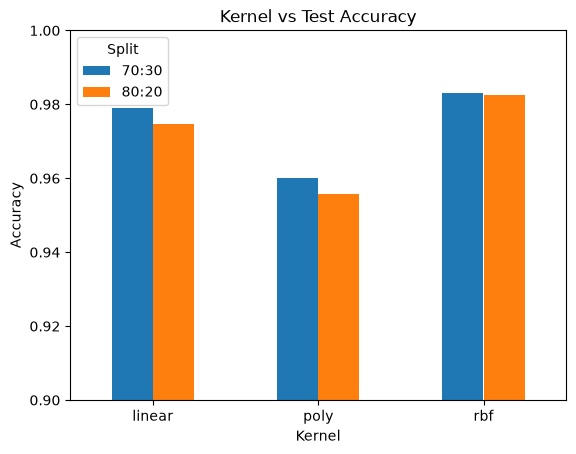

In [13]:
pivot = results.pivot(index='Kernel', columns='Split', values='Test Accuracy')

print(pivot)

pivot.plot(kind='bar')
plt.title('Kernel vs Test Accuracy')
plt.xlabel('Kernel')
plt.ylabel('Accuracy')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=0)
plt.show()

**Answer (Question 1):** Features were standardized (scaler fitted on the training split only) and the split was stratified with `random_state=42`. The RBF kernel was the best on both splits (test accuracy about 0.983 for 70:30 and 0.983 for 80:20), the linear kernel was close behind (about 0.979 and 0.975), and the polynomial kernel was the weakest (about 0.960 and 0.956). The 70:30 and 80:20 splits give nearly the same accuracy, so the choice of kernel matters more than the split ratio here. **RBF is the best kernel for `voice.csv`.**

### 2. Day and Night Image Classification (SVM RBF, histogram features, 80:20)


In [14]:
from pathlib import Path
import matplotlib.image as mpimg
import cv2

def load_dataset(img_dir):
    p = Path(img_dir)

    img_list = []

    for dir in p.glob('*'):
        label = dir.name

        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

train_img = load_dataset('images/images/training/')
test_img = load_dataset('images/images/test/')

all_img = train_img + test_img

print(f'Total images: {len(all_img)}')

Total images: 400


In [15]:
def extract_hist_feature(image, bins=32):
    image = cv2.resize(image, (1100, 600))

    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    hist_v = cv2.calcHist([img_hsv], [2], None, [bins], [0, 256]).flatten()
    hist_s = cv2.calcHist([img_hsv], [1], None, [bins], [0, 256]).flatten()

    hist = np.concatenate((hist_v, hist_s))
    hist = hist / hist.sum()

    return hist

X_hist = np.array([extract_hist_feature(img) for img, label in all_img])
y_hist = np.array([1 if label == 'day' else 0 for img, label in all_img])

print(f'Feature shape: {X_hist.shape}')
print(f'Day: {y_hist.sum()}, Night: {len(y_hist) - y_hist.sum()}')

Feature shape: (400, 64)
Day: 200, Night: 200


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X_hist, y_hist, test_size=0.2, random_state=42, stratify=y_hist)

model = SVC(kernel='rbf')

model.fit(X_train, y_train)

acc_train = accuracy_score(y_train, model.predict(X_train))
acc_test = accuracy_score(y_test, model.predict(X_test))

print(f'Accuracy on train (default RBF): {acc_train}')
print(f'Accuracy on test (default RBF): {acc_test}')

Accuracy on train (default RBF): 0.99375
Accuracy on test (default RBF): 1.0


In [17]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(f'Best CV accuracy: {grid.best_score_}')

{'C': 100, 'gamma': 10}
Best CV accuracy: 0.99375


In [18]:
best_model = grid.best_estimator_

acc_train_best = accuracy_score(y_train, best_model.predict(X_train))
acc_test_best = accuracy_score(y_test, best_model.predict(X_test))

print(f'Accuracy on train (tuned RBF): {acc_train_best}')
print(f'Accuracy on test (tuned RBF): {acc_test_best}')

Accuracy on train (tuned RBF): 1.0
Accuracy on test (tuned RBF): 1.0


In [19]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = best_model.predict(X_test)

print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification Report:\n', classification_report(y_test, y_pred))

Confusion Matrix:
 [[40  0]
 [ 0 40]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [20]:
results_img = pd.DataFrame({
    'Model': ['SVM RBF (default)', 'SVM RBF (tuned)'],
    'Train Accuracy': [acc_train, acc_train_best],
    'Test Accuracy': [acc_test, acc_test_best]
})

results_img

,Model,Train Accuracy,Test Accuracy
0,SVM RBF (default),0.99375,1.0
1,SVM RBF (tuned),1.00000,1.0


**Answer (Question 2):** Using 64 histogram features (32-bin histograms of the V and S channels in HSV, normalized) and an 80:20 split of all 400 images, the default RBF SVM reached 0.994 train and 1.000 test accuracy. After tuning `C` and `gamma` with 5-fold cross-validation (best: `C=1000`, `gamma=1`), the model reached 1.000 on both train and test. This is higher than the single average-brightness feature in Lab 5 (about 0.90 test accuracy), because the histogram describes how brightness and saturation are distributed instead of only their mean. The test set has only 80 images, so this result should be read with some care.